In [1]:
%pip install joblib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.svm import SVC

In [3]:
from pathlib import Path

In [4]:
#Yellow fever simulated messy data

df = pd.read_excel("Yellow fever simulated messy data.xlsx")
# First and last records
display(df.head())
display(df.tail())

,Case SN,Case ID,EPID number,External ID,External Token,Internal Token,Disease,Disease name,Disease variant,Person ID,...,Latest sample final laboratory result,Number of events,Latest event ID,Latest event status,Latest event title,Negative test result for disease,Information provided by physician,Verification of different pathogen,Reporting user,Reporting user roles
0,1,YF-2024-000001,NIE-EDO-000001,NaN,S27PLPJC4Z9S,WWLJPHCMDD4B,YF,Yellow fever,NaN,P-000001,...,Negative,4,EV-000001,Open,Case investigation,Yes,Unknown,Yes,Disease Surveillance and Notification Officer,Clinician
1,2,YF-2024-000002,NIE-RIV-000002,NaN,QQ33Q0QKH1K2,ON2FPRR8WNPM,YF,Yellow fever,NaN,P-000002,...,Negative,2,EV-000002,Under review,Case investigation,Yes,Unknown,No,Facility Focal Person,Clinician
2,3,YF-2022-000003,NIE-LAG-000003,EXT-465769,P7ZPBD1FOE43,N1YDYVDJI6GI,YF,Yellow fever,NaN,P-000003,...,Positive,0,EV-000003,Open,Laboratory follow-up,No,Yes,No,Disease Surveillance and Notification Officer,Surveillance Officer
3,4,YF-2025-000004,NIE-ANA-000004,NaN,UZPJGRMWJ1NB,9KA61EKC0OUL,YF,Yellow fever,NaN,P-000004,...,Negative,0,EV-000004,Closed,Contact tracing,Yes,Unknown,Yes,Surveillance Officer,Surveillance Officer
4,5,YF-2025-000005,NIE-EDO-000005,EXT-872053,T1GR4A5LA4TW,W1EB5HSJJ1AC,YF,Dengue-like illness,NaN,P-000005,...,Positive,4,EV-000005,Closed,Case investigation,No,Yes,No,Surveillance Officer,DSNO


,Case SN,Case ID,EPID number,External ID,External Token,Internal Token,Disease,Disease name,Disease variant,Person ID,...,Latest sample final laboratory result,Number of events,Latest event ID,Latest event status,Latest event title,Negative test result for disease,Information provided by physician,Verification of different pathogen,Reporting user,Reporting user roles
4995,4996,YF-2022-004996,NIE-ANA-004996,EXT-408152,VEDQNKRHXLNR,IWV9D5VPZ3UN,YF,Dengue-like illness,NaN,P-004996,...,Positive,0,EV-004996,Closed,Routine review,No,Unknown,Yes,Facility Focal Person,Clinician
4996,4997,YF-2023-004997,NIE-LAG-004997,NaN,NaN,MJ9P7UHYVZJV,YF,Malaria,NaN,P-004997,...,Positive,4,EV-004997,Open,Routine review,No,Unknown,No,Disease Surveillance and Notification Officer,DSNO
4997,4998,YF-2023-004998,NIE-KOG-004998,EXT-710166,XZTOQ0ZZJ2DD,OREZT9CWBRW8,YF,Yellow fever,NaN,P-004998,...,Negative,3,EV-004998,Closed,Case investigation,Yes,Unknown,Unknown,Disease Surveillance and Notification Officer,Clinician
4998,4999,YF-2024-004999,NIE-ENU-004999,EXT-427479,YLREXQSIUEAN,TT1RUP7WH1G7,YF,Yellow fever,NaN,P-004999,...,Positive,4,EV-004999,Under review,Case investigation,No,No,No,Surveillance Officer,Surveillance Officer
4999,5000,YF-2023-005000,NIE-KOG-005000,EXT-502670,NLV8SLKLEKQ9,Q4ZTMMVXG4DZ,YF,Yellow fever,NaN,P-005000,...,Positive,3,EV-005000,Closed,Routine review,No,No,Unknown,Disease Surveillance and Notification Officer,Clinician


In [5]:
# Column names
for number, column in enumerate(df.columns, start=1):
    print(number, repr(column))



1 'Case SN'
2 'Case ID'
3 'EPID number'
4 'External ID'
5 'External Token'
6 'Internal Token'
7 'Disease'
8 'Disease name'
9 'Disease variant'
10 'Person ID'
11 'First name'
12 'Last name'
13 'Sex'
14 'Pregnancy'
15 'Trimester'
16 'Postpartum'
17 'Age'
18 'Age group'
19 'Date of birth (year / month / day)'
20 'Date of report (dd/MM/yyyy)'
21 'Responsible state'
22 'Responsible LGA'
23 'Responsible ward'
24 'State'
25 'LGA'
26 'Ward'
27 'Facility type'
28 'Facility'
29 'Facility name & description'
30 'Place of initial detection'
31 'Case classification'
32 'Clinical confirmation'
33 'Epidemiological confirmation'
34 'Laboratory diagnostic confirmation'
35 'Investigation status'
36 'Date of investigation (dd/MM/yyyy)'
37 'Outcome of case'
38 'Date of outcome (dd/MM/yyyy)'
39 'Sequelae'
40 'Quarantine'
41 'Help needed in quarantine?'
42 'Quarantine period extended?'
43 'Quarantine period reduced?'
44 'Classification of source case'
45 'Associated with outbreak?'
46 'Admitted as inpatient

In [6]:
# Data types and non-missing counts
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Columns: 135 entries, Case SN to Reporting user roles
dtypes: float64(8), int64(3), object(1), str(123)
memory usage: 5.1+ MB


In [7]:
# Summary of numerical columns
display(df.describe().T)



,count,mean,std,min,25%,50%,75%,max
Case SN,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Disease variant,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Trimester,123.0,2.097561,0.843632,1.0,1.00,2.0,3.00,3.0
Age,5000.0,31.738600,55.030180,-5.0,15.00,28.0,41.00,999.0
Facility name & description,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of discharge or transfer (dd/MM/yyyy),0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
House number,2492.0,125.510032,72.125367,1.0,63.00,126.0,188.00,249.0
Number of doses,2847.0,1.016157,0.825893,0.0,0.00,1.0,2.00,2.0
Vaccine name details,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weight (kg),4611.0,61.354804,16.582245,2.0,50.10,61.1,72.80,114.8


In [8]:
# Summary of categorical columns
display(df.describe)

<bound method NDFrame.describe of       Case SN         Case ID     EPID number External ID External Token  \
0           1  YF-2024-000001  NIE-EDO-000001         NaN   S27PLPJC4Z9S   
1           2  YF-2024-000002  NIE-RIV-000002         NaN   QQ33Q0QKH1K2   
2           3  YF-2022-000003  NIE-LAG-000003  EXT-465769   P7ZPBD1FOE43   
3           4  YF-2025-000004  NIE-ANA-000004         NaN   UZPJGRMWJ1NB   
4           5  YF-2025-000005  NIE-EDO-000005  EXT-872053   T1GR4A5LA4TW   
...       ...             ...             ...         ...            ...   
4995     4996  YF-2022-004996  NIE-ANA-004996  EXT-408152   VEDQNKRHXLNR   
4996     4997  YF-2023-004997  NIE-LAG-004997         NaN            NaN   
4997     4998  YF-2023-004998  NIE-KOG-004998  EXT-710166   XZTOQ0ZZJ2DD   
4998     4999  YF-2024-004999  NIE-ENU-004999  EXT-427479   YLREXQSIUEAN   
4999     5000  YF-2023-005000  NIE-KOG-005000  EXT-502670   NLV8SLKLEKQ9   

     Internal Token Disease         Disease name  Dis

In [9]:
print("Duplicate column names:",
      df.columns[df.columns.duplicated()].tolist())


Duplicate column names: []


In [10]:

# Missing values per column
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
    "data_type": df.dtypes.astype(str)})

missing_report = missing_report.sort_values(
    "missing_percent", ascending=False)

display(missing_report.head(50))

# Columns that are entirely empty
empty_columns = df.columns[df.isna().all()].tolist()

print("Completely empty columns:", len(empty_columns))
print(empty_columns)

# Columns with only one observed value
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=True) <= 1]

print("Columns with zero or one observed value:")
print(constant_columns)


,missing_count,missing_percent,unique_values,data_type
Vaccine name details,5000,100.00,0,float64
Facility name & description,5000,100.00,0,float64
Disease variant,5000,100.00,0,float64
Date of discharge or transfer (dd/MM/yyyy),5000,100.00,0,float64
Trimester,4877,97.54,3,float64
Postpartum,4837,96.74,3,str
Date of death (dd/MM/yyyy),4704,94.08,274,str
Burial of case,4704,94.08,3,str
Vaccine name,3625,72.50,1,str
ATC code,3625,72.50,1,str


Completely empty columns: 4
['Disease variant', 'Facility name & description', 'Date of discharge or transfer (dd/MM/yyyy)', 'Vaccine name details']
Columns with zero or one observed value:
['Disease', 'Disease variant', 'Facility name & description', 'Date of discharge or transfer (dd/MM/yyyy)', 'Vaccine name', 'Vaccine name details', 'ATC code']


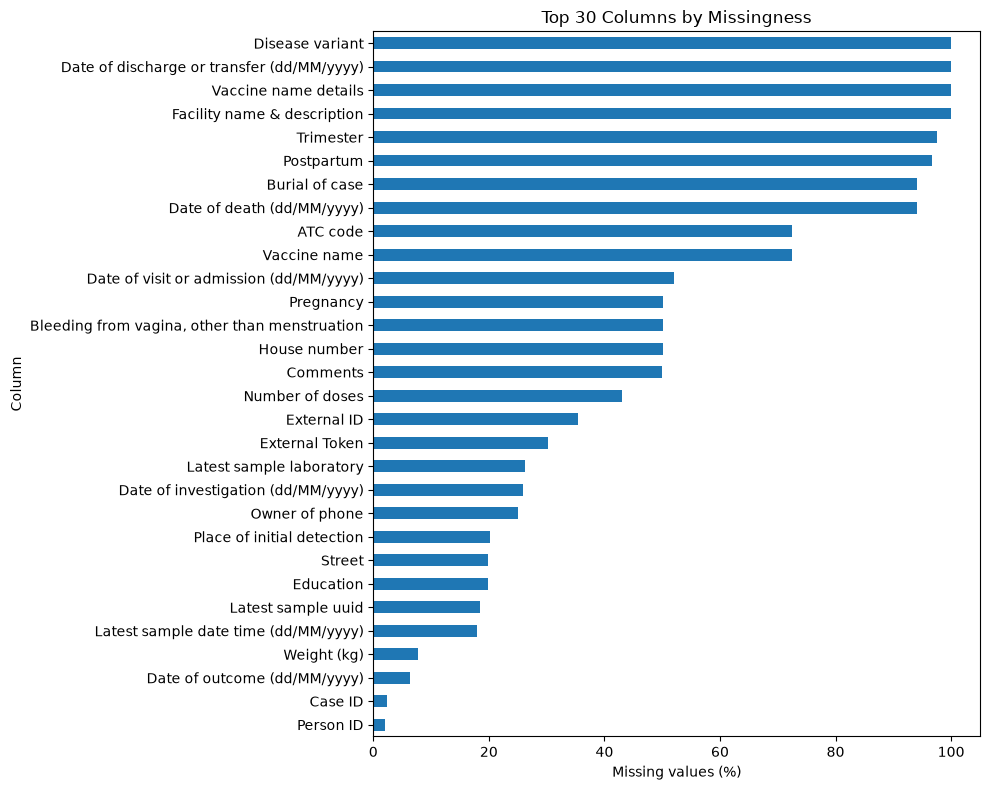

In [11]:
missing_percent = (
    df.isna().mean().mul(100)
    .sort_values(ascending=False))

missing_percent = missing_percent[missing_percent > 0].head(30)

missing_percent.sort_values().plot(
    kind="barh",
    figsize=(10, 8))

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Top 30 Columns by Missingness")
plt.tight_layout()
plt.show()

In [12]:
# 4.1 Exact duplicate rows
exact_duplicates = df.duplicated()

print("Exact duplicate rows:", exact_duplicates.sum())

# Inspect exact duplicate rows before deciding what to do
display(df.loc[exact_duplicates].head(10))

# 4.2 Check uniqueness and missingness of identifiers
id_columns = [
    "Case SN",
    "Case ID",
    "EPID number",
    "External ID",
    "External Token",
    "Internal Token",
    "Person ID"]

for col in id_columns:
     if col in df.columns:
        print(f"\n{col}")
        print("Missing:", df[col].isna().sum())
        print("Repeated non-missing values:",
              df[col].dropna().duplicated().sum())
        print("Unique non-missing values:",
              df[col].nunique(dropna=True))

Exact duplicate rows: 0


,Case SN,Case ID,EPID number,External ID,External Token,Internal Token,Disease,Disease name,Disease variant,Person ID,...,Latest sample final laboratory result,Number of events,Latest event ID,Latest event status,Latest event title,Negative test result for disease,Information provided by physician,Verification of different pathogen,Reporting user,Reporting user roles



Case SN
Missing: 0
Repeated non-missing values: 0
Unique non-missing values: 5000

Case ID
Missing: 120
Repeated non-missing values: 0
Unique non-missing values: 4880

EPID number
Missing: 0
Repeated non-missing values: 0
Unique non-missing values: 5000

External ID
Missing: 1774
Repeated non-missing values: 5
Unique non-missing values: 3221

External Token
Missing: 1512
Repeated non-missing values: 0
Unique non-missing values: 3488

Internal Token
Missing: 0
Repeated non-missing values: 0
Unique non-missing values: 5000

Person ID
Missing: 100
Repeated non-missing values: 0
Unique non-missing values: 4900


In [13]:
if "Case ID" in df.columns:
    repeated_case_ids = df[
        df["Case ID"].notna()
        & df["Case ID"].duplicated(keep=False)
    ].sort_values("Case ID")

    display(repeated_case_ids.head(20))

,Case SN,Case ID,EPID number,External ID,External Token,Internal Token,Disease,Disease name,Disease variant,Person ID,...,Latest sample final laboratory result,Number of events,Latest event ID,Latest event status,Latest event title,Negative test result for disease,Information provided by physician,Verification of different pathogen,Reporting user,Reporting user roles


In [14]:
df = df.drop_duplicates().copy()

In [15]:


# Date columns recorded in day/month/year format
dmy_date_columns = [
    "Date of report (dd/MM/yyyy)",
    "Date of investigation (dd/MM/yyyy)",
    "Date of outcome (dd/MM/yyyy)",
    "Date of visit or admission (dd/MM/yyyy)",
    "Date of discharge or transfer (dd/MM/yyyy)",
    "Date of death (dd/MM/yyyy)",
    "Date of first vaccination (dd/MM/yyyy)",
    "Date of last vaccination (dd/MM/yyyy)",
    "Date of symptom onset (dd/MM/yyyy)",
    "Latest sample date time (dd/MM/yyyy)",
    "2nd latest sample date time (dd/MM/yyyy)",
    "3rd latest sample date time (dd/MM/yyyy)",
    "Quarantine start (dd/MM/yyyy)",
    "Quarantine end (dd/MM/yyyy)",
    "Previous quarantine end (dd/MM/yyyy)"
]

# Convert date strings to datetime
for col in dmy_date_columns:
    if col in df.columns:
        values = (
            df[col]
            .astype("string")
            .str.strip()
            .replace({
                "": pd.NA,
                "########": pd.NA,
                "nan": pd.NA,
                "NaT": pd.NA,
                "None": pd.NA
            })
        )

        df[col] = pd.to_datetime(
            values,
            format="%d/%m/%Y",
            errors="coerce"
        )

# Date of birth uses year-month-day
dob_col = "Date of birth (year / month / day)"

if dob_col in df.columns:
    df[dob_col] = pd.to_datetime(
        df[dob_col],
        format="%Y-%m-%d",
        errors="coerce"
    )

# Check the additional camel-case date columns
for col in ["dateOfInvestigation (dd/MM/yyyy)",
            "dateOfOutcome (dd/MM/yyyy)"]:
    if col in df.columns:
        values = (
            df[col].astype("string").str.strip()
            .replace({"": pd.NA, "########": pd.NA})
        )
        df[col] = pd.to_datetime(
            values, format="%d/%m/%Y", errors="coerce"
        )

# Verify the resulting data types
converted_dates = [
    col for col in df.columns
    if col in dmy_date_columns
    or col == dob_col
    or col in [
        "dateOfInvestigation (dd/MM/yyyy)",
        "dateOfOutcome (dd/MM/yyyy)"
    ]
]

display(df[converted_dates].dtypes)
display(df[converted_dates].head())



Date of birth (year / month / day)            datetime64[us]
Date of report (dd/MM/yyyy)                   datetime64[us]
Date of investigation (dd/MM/yyyy)            datetime64[us]
Date of outcome (dd/MM/yyyy)                  datetime64[us]
Date of visit or admission (dd/MM/yyyy)       datetime64[us]
Date of discharge or transfer (dd/MM/yyyy)     datetime64[s]
Date of death (dd/MM/yyyy)                    datetime64[us]
Date of symptom onset (dd/MM/yyyy)            datetime64[us]
Latest sample date time (dd/MM/yyyy)          datetime64[us]
dtype: object

,Date of birth (year / month / day),Date of report (dd/MM/yyyy),Date of investigation (dd/MM/yyyy),Date of outcome (dd/MM/yyyy),Date of visit or admission (dd/MM/yyyy),Date of discharge or transfer (dd/MM/yyyy),Date of death (dd/MM/yyyy),Date of symptom onset (dd/MM/yyyy),Latest sample date time (dd/MM/yyyy)
0,1988-01-02,2024-05-05,2024-05-07,2024-06-01,NaT,NaT,NaT,2024-04-24,2024-05-06
1,2017-12-13,2024-10-01,2024-10-03,2024-10-21,2024-10-01,NaT,NaT,2024-09-20,2024-10-03
2,1998-12-03,2022-04-02,2022-04-08,2022-04-21,NaT,NaT,NaT,2022-03-23,2022-04-05
3,1990-10-13,2025-10-17,NaT,2025-10-21,NaT,NaT,NaT,2025-10-15,NaT
4,1980-08-23,2025-05-08,2025-05-11,NaT,2025-05-08,NaT,NaT,2025-05-06,2025-05-11


In [16]:
date_check = []

for col in converted_dates:
    date_check.append({
        "column": col,
        "missing_after_conversion": df[col].isna().sum(),
        "earliest_date": df[col].min(),
        "latest_date": df[col].max()
    })

display(pd.DataFrame(date_check))

,column,missing_after_conversion,earliest_date,latest_date
0,Date of birth (year / month / day),0,1022-03-27,2029-12-14
1,Date of report (dd/MM/yyyy),162,2021-01-01,2025-12-31
2,Date of investigation (dd/MM/yyyy),1299,2021-01-01,2026-01-05
3,Date of outcome (dd/MM/yyyy),319,2021-01-06,2026-01-28
4,Date of visit or admission (dd/MM/yyyy),2599,2021-01-04,2025-12-31
5,Date of discharge or transfer (dd/MM/yyyy),5000,NaT,NaT
6,Date of death (dd/MM/yyyy),4704,2021-01-12,2026-01-08
7,Date of symptom onset (dd/MM/yyyy),0,2020-12-21,2025-12-30
8,Latest sample date time (dd/MM/yyyy),895,2021-01-03,2026-01-08


In [17]:


report_col = "Date of report (dd/MM/yyyy)"
investigation_col = "Date of investigation (dd/MM/yyyy)"
onset_col = "Date of symptom onset (dd/MM/yyyy)"
sample_col = "Latest sample date time (dd/MM/yyyy)"
death_col = "Date of death (dd/MM/yyyy)"

# Each flag marks a record for review; it does not delete it.
if report_col in df.columns and onset_col in df.columns:
    df["flag_report_before_onset"] = (
        df[report_col].notna()
        & df[onset_col].notna()
        & (df[report_col] < df[onset_col])
    )

if investigation_col in df.columns and report_col in df.columns:
    df["flag_investigation_before_report"] = (
        df[investigation_col].notna()
        & df[report_col].notna()
        & (df[investigation_col] < df[report_col])
    )

if sample_col in df.columns and onset_col in df.columns:
    df["flag_sample_before_onset"] = (
        df[sample_col].notna()
        & df[onset_col].notna()
        & (df[sample_col] < df[onset_col])
    )

if death_col in df.columns and onset_col in df.columns:
    df["flag_death_before_onset"] = (
        df[death_col].notna()
        & df[onset_col].notna()
        & (df[death_col] < df[onset_col])
    )

flag_columns = [c for c in df.columns if c.startswith("flag_")]

for col in flag_columns:
    print(col, ":", df[col].sum(), "records flagged")


flag_report_before_onset : 0 records flagged
flag_investigation_before_report : 0 records flagged
flag_sample_before_onset : 0 records flagged
flag_death_before_onset : 0 records flagged


In [18]:

if report_col in df.columns and onset_col in df.columns:
    df["reporting_delay_days"] = (
        df[report_col] - df[onset_col]
    ).dt.days

    # Negative delay requires review, not automatic deletion
    df.loc[
        df["reporting_delay_days"] < 0,
        "reporting_delay_days"
    ] = np.nan

if investigation_col in df.columns and report_col in df.columns:
    df["investigation_delay_days"] = (
        df[investigation_col] - df[report_col]
    ).dt.days

    df.loc[
        df["investigation_delay_days"] < 0,
        "investigation_delay_days"
    ] = np.nan

if onset_col in df.columns:
    df["onset_year"] = df[onset_col].dt.year
    df["onset_month"] = df[onset_col].dt.month
    df["onset_quarter"] = df[onset_col].dt.quarter
    df["onset_day_of_week"] = df[onset_col].dt.day_name()

display(df[[
    c for c in [
        "reporting_delay_days",
        "investigation_delay_days",
        "onset_year",
        "onset_month"
    ] if c in df.columns
]].describe().T)



,count,mean,std,min,25%,50%,75%,max
reporting_delay_days,4838.0,6.982431,4.313522,0.0,3.0,7.0,11.0,14.0
investigation_delay_days,3589.0,3.563110,2.293838,0.0,2.0,4.0,6.0,7.0
onset_year,5000.0,2022.988400,1.421784,2020.0,2022.0,2023.0,2024.0,2025.0
onset_month,5000.0,6.545600,3.443413,1.0,4.0,7.0,9.0,12.0


In [19]:


# Preserve the original recorded age
df["Age_original"] = df["Age"]

# Convert to numeric
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# Flag ages outside the selected plausible range
df["flag_invalid_age"] = (
    df["Age"].notna()
    & ~df["Age"].between(0, 120)
)

print("Invalid ages:", df["flag_invalid_age"].sum())

# Replace implausible ages with missing values
df.loc[df["flag_invalid_age"], "Age"] = np.nan

# Calculate completed age in years from DOB and symptom onset
if dob_col in df.columns and onset_col in df.columns:
    dob = df[dob_col]
    onset = df[onset_col]

    valid_dates = (
        dob.notna()
        & onset.notna()
        & (dob <= onset)
    )

    # Completed age, accounting for whether the birthday has occurred
    age_from_dates = (
        onset.dt.year - dob.dt.year
        - (
            (onset.dt.month < dob.dt.month)
            | (
                (onset.dt.month == dob.dt.month)
                & (onset.dt.day < dob.dt.day)
            )
        ).astype("Int64")
    )

    df["age_from_dates"] = age_from_dates.where(valid_dates).astype("Float64")

    # Flag disagreement of 2 or more years for review
    df["flag_age_disagreement"] = (
        df["Age"].notna()
        & df["age_from_dates"].notna()
        & ((df["Age"] - df["age_from_dates"]).abs() >= 2)
    )

    print("Age disagreements:",
          df["flag_age_disagreement"].sum())

# Use the date-derived age only when it is valid and the recorded age is missing
df["Age_clean"] = df["Age"].combine_first(df["age_from_dates"])

display(
    df[["Age_original", "Age", "age_from_dates", "Age_clean"]]
    .describe().T
)


Invalid ages: 51
Age disagreements: 0


,count,mean,std,min,25%,50%,75%,max
Age_original,5000.0,31.7386,55.03018,-5.0,15.0,28.0,41.0,999.0
Age,4949.0,28.650636,18.483311,0.0,15.0,28.0,40.0,120.0
age_from_dates,4975.0,31.877186,55.067849,0.0,15.0,28.0,41.0,999.0
Age_clean,4983.0,31.860526,55.040721,0.0,15.0,28.0,41.0,999.0


In [20]:

if "Age group" in df.columns:
    print("Recorded age-group categories:")
    print(df["Age group"].value_counts(dropna=False))

    # Compare against the cleaned age, using broad age bands
    df["Age_group_from_age"] = pd.cut(
        df["Age_clean"],
        bins=[-1, 4, 14, 24, 44, 64, 120],
        labels=["0-4", "5-14", "15-24", "25-44", "45-64", "65+"]
    )

    display(pd.crosstab(
        df["Age group"],
        df["Age_group_from_age"],
        margins=True,
        dropna=False
    ))


Recorded age-group categories:
Age group
25-44       1917
15-24        885
45-64        755
5-14         602
0-4          561
65+          173
adult         33
Unknown       27
15 to 24      27
NaN           20
Name: count, dtype: int64


Age_group_from_age,0-4,5-14,15-24,25-44,45-64,65+,All
Age group,,,,,,,
NaN,3,1,4,8,3,1,20
0-4,544,0,0,0,0,0,561
15 to 24,6,2,4,10,5,0,27
15-24,0,0,885,0,0,0,885
25-44,0,0,0,1917,0,0,1917
45-64,0,0,0,0,755,0,755
5-14,0,602,0,0,0,0,602
65+,0,0,0,0,0,139,173
Unknown,3,6,5,6,6,1,27


In [21]:

# Clean whitespace in text columns
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Standardize common missing-value placeholders
missing_tokens = [
    "", "NA", "N/A", "NULL", "NONE", "NAN"
]

for col in text_columns:
    df[col] = df[col].replace(
        missing_tokens, pd.NA, regex=False
    )

# Inspect selected categorical fields
for col in [
    "Sex",
    "Pregnancy",
    "State",
    "Responsible state",
    "Case classification",
    "Clinical confirmation",
    "Epidemiological confirmation",
    "Investigation status",
    "Outcome of case",
    "Vaccination status"
]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False))



--- Sex ---
Sex
Male      2456
Female    2426
female      65
male        53
Name: count, dtype: Int64

--- Pregnancy ---
Pregnancy
<NA>    2509
No      2328
Yes      163
Name: count, dtype: Int64

--- State ---
State
Lagos      840
Edo        836
Rivers     834
Enugu      809
Anambra    792
Kogi       774
edo         23
anambra     23
lagos       22
enugu       21
kogi        17
rivers       9
Name: count, dtype: Int64

--- Responsible state ---
Responsible state
Lagos      850
Edo        847
Rivers     835
Enugu      814
Anambra    800
Kogi       783
ENUGU       16
ANAMBRA     15
LAGOS       12
EDO         12
KOGI         8
RIVERS       8
Name: count, dtype: Int64

--- Case classification ---
Case classification
Suspected    1798
Discarded    1371
Confirmed    1362
Probable      469
Name: count, dtype: Int64

--- Clinical confirmation ---
Clinical confirmation
Yes        1702
Unknown    1678
No         1620
Name: count, dtype: Int64

--- Epidemiological confirmation ---
Epidemiologic

In [22]:

# Example: standardize sex values
if "Sex" in df.columns:
    sex_map = {
        "female": "Female",
        "f": "Female",
        "male": "Male",
        "m": "Male"
    }

    df["Sex"] = df["Sex"].replace(
        sex_map,
        regex=False
    )

# Example: standardize laboratory-result labels
target_col = "Latest sample final laboratory result"

if target_col in df.columns:
    df[target_col] = (
        df[target_col]
        .astype("string")
        .str.strip()
        .str.casefold()
        .replace({
            "positive": "Positive",
            "negative": "Negative",
            "inconclusive": "Inconclusive",
            "indeterminate": "Inconclusive"
        })
    )

    print(df[target_col].value_counts(dropna=False))


Latest sample final laboratory result
Negative        2698
Positive        1346
Inconclusive     309
pending          301
not tested       296
########          50
Name: count, dtype: Int64


In [23]:

symptom_columns = [
    "Abdominal pain",
    "Altered level of consciousness",
    "Anorexia/loss of appetite",
    "Backache",
    "Blood in stool",
    "Blood in urine (hematuria)",
    "Cough",
    "Diarrhea",
    "Fever",
    "Headache",
    "Hemorrhagic syndrome",
    "Jaundice",
    "Malaise",
    "Muscle pain",
    "Nausea",
    "Vomiting"
]

symptom_columns = [
    col for col in symptom_columns if col in df.columns
]

for col in symptom_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))



Abdominal pain
Abdominal pain
No     3862
Yes    1138
Name: count, dtype: Int64

Altered level of consciousness
Altered level of consciousness
No     4737
Yes     263
Name: count, dtype: Int64

Anorexia/loss of appetite
Anorexia/loss of appetite
Yes        1686
Unknown    1670
No         1644
Name: count, dtype: Int64

Backache
Backache
No         1692
Yes        1665
Unknown    1643
Name: count, dtype: Int64

Blood in stool
Blood in stool
No     4877
Yes     123
Name: count, dtype: Int64

Blood in urine (hematuria)
Blood in urine (hematuria)
No     4886
Yes     114
Name: count, dtype: Int64

Cough
Cough
No     4241
Yes     759
Name: count, dtype: Int64

Diarrhea
Diarrhea
No     4100
Yes     900
Name: count, dtype: Int64

Fever
Fever
Yes     4123
No       672
<NA>      78
1         50
yes       40
YES       37
Name: count, dtype: Int64

Headache
Headache
Yes    3096
No     1904
Name: count, dtype: Int64

Hemorrhagic syndrome
Hemorrhagic syndrome
No     4550
Yes     450
Name: count, dt

In [24]:

numeric_columns = [
    "Age",
    "Weight (kg)",
    "Number of doses",
    "Current body temperature in Â° C"
]

for col in numeric_columns:
    if col in df.columns:
        # Conversion errors become missing rather than being guessed
        df[col] = pd.to_numeric(df[col], errors="coerce")

for col in numeric_columns:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].describe())
        print("Missing:", df[col].isna().sum())



--- Age ---
count    4949.000000
mean       28.650636
std        18.483311
min         0.000000
25%        15.000000
50%        28.000000
75%        40.000000
max       120.000000
Name: Age, dtype: float64
Missing: 51

--- Weight (kg) ---
count    4611.000000
mean       61.354804
std        16.582245
min         2.000000
25%        50.100000
50%        61.100000
75%        72.800000
max       114.800000
Name: Weight (kg), dtype: float64
Missing: 389

--- Number of doses ---
count    2847.000000
mean        1.016157
std         0.825893
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         2.000000
Name: Number of doses, dtype: float64
Missing: 2153

--- Current body temperature in Â° C ---
count       4920.0
mean     38.531037
std       5.730267
min           -2.0
25%           37.7
50%           38.4
75%           39.1
max           99.0
Name: Current body temperature in Â° C, dtype: Float64
Missing: 80


In [25]:

# Weight: use a broad screening range, not a clinical diagnosis
if "Weight (kg)" in df.columns:
    df["flag_suspicious_weight"] = (
        df["Weight (kg)"].notna()
        & ~df["Weight (kg)"].between(0.5, 300)
    )

# Body temperature: inspect broad plausibility bounds
temp_col = "Current body temperature in Â° C"

if temp_col in df.columns:
    df["flag_suspicious_temperature"] = (
        df[temp_col].notna()
        & ~df[temp_col].between(25, 45)
    )

# Dose count should not be negative or fractional
if "Number of doses" in df.columns:
    doses = df["Number of doses"]

    df["flag_invalid_doses"] = (
        doses.notna()
        & ((doses < 0) | (doses % 1 != 0))
    )

for col in [
    "flag_suspicious_weight",
    "flag_suspicious_temperature",
    "flag_invalid_doses"
]:
    if col in df.columns:
        print(col, ":", df[col].sum())


flag_suspicious_weight : 0
flag_suspicious_temperature : 59
flag_invalid_doses : 0


In [26]:
[c for c in df.columns if "temperature" in c.lower()]

['Current body temperature in Â° C',
 'Source of body temperature',
 'flag_suspicious_temperature']

In [27]:

geo_columns = [
    "State",
    "LGA",
    "Ward",
    "Responsible state",
    "Responsible LGA",
    "Responsible ward",
    "Address state",
    "Address LGA",
    "Address ward"
]

geo_columns = [col for col in geo_columns if col in df.columns]

for col in geo_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

# Inspect combinations for possible inconsistencies
if "State" in df.columns and "LGA" in df.columns:
    state_lga_combinations = (
        df.groupby(["State", "LGA"], dropna=False)
        .size()
        .reset_index(name="record_count")
        .sort_values("record_count", ascending=False)
    )

    display(state_lga_combinations.head(50))



--- State ---
State
Lagos      840
Edo        836
Rivers     834
Enugu      809
Anambra    792
Kogi       774
edo         23
anambra     23
lagos       22
enugu       21
kogi        17
rivers       9
Name: count, dtype: Int64

--- LGA ---
LGA
Idah             195
Port Harcourt    187
Akoko-Edo        182
Awgu             182
Esan Central     181
Surulere         180
Lagos Island     179
Oredo            176
Oji River        176
Alimosho         175
Udi              171
Obio/Akpor       167
Bonny            164
Eti-Osa          164
Uhunmwonde       156
Eleme            155
Okene            154
Lokoja           153
Ikwerre          153
Etsako West      150
Ikeja            149
Nsukka           147
Awka South       146
Ankpa            143
Enugu North      143
Awka North       141
Orumba North     141
Kabba/Bunu       140
Onitsha North    130
Idemili North    129
Nnewi North      116
unknown           75
Name: count, dtype: Int64

--- Ward ---
Ward
Oko          533
Umuagu       518
River

,State,LGA,record_count
20,Kogi,Idah,190
35,Rivers,Port Harcourt,184
13,Enugu,Awgu,178
29,Lagos,Surulere,177
7,Edo,Akoko-Edo,176
28,Lagos,Lagos Island,175
8,Edo,Esan Central,174
10,Edo,Oredo,173
16,Enugu,Oji River,170
25,Lagos,Alimosho,169


In [28]:

target_col = "Latest sample final laboratory result"

if target_col not in df.columns:
    raise KeyError(f"Target column not found: {target_col}")

print(df[target_col].value_counts(dropna=False))

# Check the other laboratory-related columns
lab_columns = [
    col for col in df.columns
    if "sample" in col.lower()
    or "laboratory" in col.lower()
    or "confirmation" in col.lower()
]

display(df[lab_columns].head(10))


Latest sample final laboratory result
Negative        2698
Positive        1346
Inconclusive     309
pending          301
not tested       296
########          50
Name: count, dtype: Int64


,Clinical confirmation,Epidemiological confirmation,Laboratory diagnostic confirmation,Latest sample uuid,Latest sample date time (dd/MM/yyyy),Latest sample laboratory,Latest sample final laboratory result,flag_sample_before_onset
0,Unknown,No,Negative,<NA>,2024-05-06,National Reference Lab,Negative,False
1,Yes,No,Negative,S-000002,2024-10-03,National Reference Lab,Negative,False
2,Unknown,No,Positive,S-000003,2022-04-05,National Reference Lab,Positive,False
3,No,No,Negative,<NA>,NaT,State Public Health Lab,Negative,False
4,Yes,No,Positive,<NA>,2025-05-11,State Public Health Lab,Positive,False
5,Unknown,No,Positive,S-000006,2023-04-05,<NA>,Positive,False
6,No,Yes,Inconclusive,S-000007,2021-10-15,National Reference Lab,Inconclusive,False
7,Yes,No,Negative,S-000008,2023-12-14,<NA>,Negative,False
8,Unknown,Unknown,Negative,S-000009,2022-01-21,State Public Health Lab,Negative,False
9,No,Unknown,Positive,S-000010,2023-11-05,State Public Health Lab,Positive,False


In [29]:

# Create a separate modelling dataset later; do not delete these
# inconclusive or missing-result records from df.

result = df[target_col].astype("string").str.strip().str.casefold()

df["lab_result_binary"] = result.map({
    "positive": 1,
    "negative": 0
})

print("Positive:", (df["lab_result_binary"] == 1).sum())
print("Negative:", (df["lab_result_binary"] == 0).sum())
print("Inconclusive/unrecognized/missing:",
      df["lab_result_binary"].isna().sum())


Positive: 1346
Negative: 2698
Inconclusive/unrecognized/missing: 956


In [30]:

target_counts = df["lab_result_binary"].value_counts(dropna=False)
print(target_counts)

df["lab_result_binary"].value_counts(normalize=True).mul(100).round(2)


lab_result_binary
0.0    2698
1.0    1346
NaN     956
Name: count, dtype: int64


lab_result_binary
0.0    66.72
1.0    33.28
Name: proportion, dtype: float64

In [31]:

# Candidate predictors for an early clinical assessment model.
# Confirm each variable's timing and meaning before using it.

candidate_features = [
    "Age_clean",
    "Sex",
    "State",
    "LGA",
    "Age group",
    "Vaccination status",
    "Symptomatic",
    "First symptom",
    "Fever",
    "Jaundice",
    "Headache",
    "Vomiting",
    "Nausea",
    "Fatigue/general weakness",
    "Muscle pain",
    "Joint pain or arthritis",
    "Bleeding of the gums",
    "Blood in stool",
    "Blood in urine (hematuria)",
    "Diarrhea",
    "Abdominal pain",
    "Chills or sweats",
    "Dehydration",
    "Conjunctivitis (red eyes)",
    "onset_month",
    "onset_quarter"
]

candidate_features = [
    col for col in candidate_features if col in df.columns
]

print("Candidate features:")
print(candidate_features)


Candidate features:
['Age_clean', 'Sex', 'State', 'LGA', 'Age group', 'Vaccination status', 'Symptomatic', 'First symptom', 'Fever', 'Jaundice', 'Headache', 'Vomiting', 'Nausea', 'Fatigue/general weakness', 'Muscle pain', 'Joint pain or arthritis', 'Bleeding of the gums', 'Blood in stool', 'Blood in urine (hematuria)', 'Diarrhea', 'Abdominal pain', 'Chills or sweats', 'Dehydration', 'Conjunctivitis (red eyes)', 'onset_month', 'onset_quarter']


In [32]:

quality_report = pd.DataFrame({
    "column": df.columns,
    "data_type": [str(df[c].dtype) for c in df.columns],
    "missing_count": [df[c].isna().sum() for c in df.columns],
    "missing_percent": [
        round(df[c].isna().mean() * 100, 2)
        for c in df.columns
    ],
    "unique_values": [df[c].nunique(dropna=True) for c in df.columns]
})

quality_report = quality_report.sort_values(
    "missing_percent", ascending=False
)

display(quality_report.head(50))

# Count records flagged for review
flag_columns = [
    c for c in df.columns if c.startswith("flag_")
]

if flag_columns:
    flag_summary = pd.DataFrame({
        "flag": flag_columns,
        "records_flagged": [
            int(df[c].fillna(False).sum())
            for c in flag_columns
        ]
    })
    display(flag_summary)


,column,data_type,missing_count,missing_percent,unique_values
8,Disease variant,float64,5000,100.00,0
47,Date of discharge or transfer (dd/MM/yyyy),datetime64[s],5000,100.00,0
28,Facility name & description,float64,5000,100.00,0
70,Vaccine name details,float64,5000,100.00,0
14,Trimester,float64,4877,97.54,3
15,Postpartum,string,4837,96.74,3
50,Date of death (dd/MM/yyyy),datetime64[us],4704,94.08,274
51,Burial of case,string,4704,94.08,3
69,Vaccine name,string,3625,72.50,1
71,ATC code,string,3625,72.50,1


,flag,records_flagged
0,flag_report_before_onset,0
1,flag_investigation_before_report,0
2,flag_sample_before_onset,0
3,flag_death_before_onset,0
4,flag_invalid_age,51
5,flag_age_disagreement,0
6,flag_suspicious_weight,0
7,flag_suspicious_temperature,59
8,flag_invalid_doses,0


In [33]:

print("Final working dataset shape:", df.shape)

print("\nRemaining exact duplicates:", df.duplicated().sum())

print("\nRemaining invalid ages:",
      (~df["Age"].dropna().between(0, 120)).sum()
      if "Age" in df.columns else "Age column absent")

print("\nTarget distribution:")
print(df["lab_result_binary"].value_counts(dropna=False))

print("\nDate column types:")
for col in converted_dates:
    if col in df.columns:
        print(col, "->", df[col].dtype)


Final working dataset shape: (5000, 155)

Remaining exact duplicates: 0

Remaining invalid ages: 0

Target distribution:
lab_result_binary
0.0    2698
1.0    1346
NaN     956
Name: count, dtype: int64

Date column types:
Date of birth (year / month / day) -> datetime64[us]
Date of report (dd/MM/yyyy) -> datetime64[us]
Date of investigation (dd/MM/yyyy) -> datetime64[us]
Date of outcome (dd/MM/yyyy) -> datetime64[us]
Date of visit or admission (dd/MM/yyyy) -> datetime64[us]
Date of discharge or transfer (dd/MM/yyyy) -> datetime64[s]
Date of death (dd/MM/yyyy) -> datetime64[us]
Date of symptom onset (dd/MM/yyyy) -> datetime64[us]
Latest sample date time (dd/MM/yyyy) -> datetime64[us]


In [34]:


output_dir = Path("yellow_fever_cleaning_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Cleaned dataset, retaining inconclusive and missing-result cases
df.to_csv(
    output_dir / "yellow_fever_cleaned.csv",
    index=False,
    date_format="%Y-%m-%d"
)

# 2. Data quality report
quality_report.to_csv(
    output_dir / "yellow_fever_quality_report.csv",
    index=False
)

# 3. Records flagged for review
if flag_columns:
    flagged_records = df[df[flag_columns].fillna(False).any(axis=1)]
    flagged_records.to_csv(
        output_dir / "yellow_fever_records_for_review.csv",
        index=False,
        date_format="%Y-%m-%d"
    )

# 4. Separate binary modelling dataset
model_df = df.loc[
    df["lab_result_binary"].notna()
].copy()

model_df.to_csv(
    output_dir / "yellow_fever_binary_model_data.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Files saved in:", output_dir.resolve())
print("Cleaned surveillance data:", df.shape)
print("Binary modelling data:", model_df.shape)



Files saved in: C:\Users\BLAST\Desktop\PYTHON CLASS\DATA SCIENCE NOTE\yellow_fever_cleaning_outputs
Cleaned surveillance data: (5000, 155)
Binary modelling data: (4044, 155)


In [35]:



target_col = "Latest sample final laboratory result"

# Check that the target column exists
if target_col not in df.columns:
    raise KeyError(f"Missing target column: {target_col}")

# Normalize target labels
result = (
    df[target_col]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Convert target to binary values
y_all = result.map({
    "positive": 1,
    "negative": 0
})

# Create a modelling copy with known binary outcomes
model_df = df.loc[y_all.notna()].copy()
model_df["target"] = y_all.loc[y_all.notna()].astype(int)

print("Original dataset:", df.shape)
print("Records with positive/negative results:", model_df.shape)
print("\nTarget distribution:")
print(model_df["target"].value_counts())
print("\nTarget percentages:")
print((model_df["target"].value_counts(normalize=True) * 100).round(2))


Original dataset: (5000, 155)
Records with positive/negative results: (4044, 156)

Target distribution:
target
0    2698
1    1346
Name: count, dtype: int64

Target percentages:
target
0    66.72
1    33.28
Name: proportion, dtype: float64


In [36]:

# Candidate predictors: use only columns that exist in your dataset
candidate_features = [
    "Age_clean",
    "Sex",
    "State",
    "LGA",
    "Age group",
    "Vaccination status",
    "Symptomatic",
    "First symptom",
    "Fever",
    "Jaundice",
    "Headache",
    "Vomiting",
    "Nausea",
    "Fatigue/general weakness",
    "Muscle pain",
    "Joint pain or arthritis",
    "Bleeding of the gums",
    "Blood in stool",
    "Blood in urine (hematuria)",
    "Diarrhea",
    "Abdominal pain",
    "Chills or sweats",
    "Dehydration",
    "Conjunctivitis (red eyes)",
    "onset_month",
    "onset_quarter"
]

# Keep only predictors present in the dataset
features = [
    col for col in candidate_features
    if col in model_df.columns
]

print("Number of candidate features:", len(features))
print("Features selected:")
print(features)

if len(features) == 0:
    raise ValueError(
        "No candidate features found. Check your actual column names."
    )

# Create X (predictors) and y (target)
X = model_df[features].copy()
y = model_df["target"].copy()

# Drop features that have no observed values or only one observed value
uninformative_features = [
    col for col in X.columns
    if X[col].notna().sum() == 0
    or X[col].nunique(dropna=True) <= 1
]

print("Features removed as uninformative:", uninformative_features)

X = X.drop(columns=uninformative_features)

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)


Number of candidate features: 26
Features selected:
['Age_clean', 'Sex', 'State', 'LGA', 'Age group', 'Vaccination status', 'Symptomatic', 'First symptom', 'Fever', 'Jaundice', 'Headache', 'Vomiting', 'Nausea', 'Fatigue/general weakness', 'Muscle pain', 'Joint pain or arthritis', 'Bleeding of the gums', 'Blood in stool', 'Blood in urine (hematuria)', 'Diarrhea', 'Abdominal pain', 'Chills or sweats', 'Dehydration', 'Conjunctivitis (red eyes)', 'onset_month', 'onset_quarter']
Features removed as uninformative: []
Final X shape: (4044, 26)
Final y shape: (4044,)


In [37]:

display(X.head())

print("\nData types:")
print(X.dtypes)

print("\nMissing percentage:")
display((X.isna().mean() * 100).sort_values(ascending=False).round(2))

print("\nTarget classes:")
print(y.value_counts())


,Age_clean,Sex,State,LGA,Age group,Vaccination status,Symptomatic,First symptom,Fever,Jaundice,...,Bleeding of the gums,Blood in stool,Blood in urine (hematuria),Diarrhea,Abdominal pain,Chills or sweats,Dehydration,Conjunctivitis (red eyes),onset_month,onset_quarter
0,36.0,Female,Edo,Uhunmwonde,25-44,Unvaccinated,Yes,Fever,Yes,No,...,No,No,No,No,No,Yes,Yes,Unknown,4,2
1,6.0,Female,Rivers,Bonny,5-14,Unknown,Yes,Fatigue,Yes,No,...,No,No,Yes,Yes,No,No,Unknown,Yes,9,3
2,23.0,Male,Lagos,Alimosho,15-24,Vaccinated,Yes,Fever,Yes,No,...,No,No,No,Yes,No,No,Unknown,Yes,3,1
3,35.0,Female,Anambra,Nnewi North,25-44,Unvaccinated,Yes,Headache,Yes,Yes,...,No,No,No,No,No,No,Yes,No,10,4
4,44.0,Male,Edo,Etsako West,25-44,Unvaccinated,Yes,Headache,Yes,No,...,No,No,No,No,Yes,Unknown,Yes,No,5,2



Data types:
Age_clean                     Float64
Sex                            string
State                          string
LGA                            string
Age group                      string
Vaccination status             string
Symptomatic                    string
First symptom                  string
Fever                          string
Jaundice                       string
Headache                       string
Vomiting                       string
Nausea                         string
Fatigue/general weakness       string
Muscle pain                    string
Joint pain or arthritis        string
Bleeding of the gums           string
Blood in stool                 string
Blood in urine (hematuria)     string
Diarrhea                       string
Abdominal pain                 string
Chills or sweats               string
Dehydration                    string
Conjunctivitis (red eyes)      string
onset_month                     int32
onset_quarter                   int32

Jaundice                      1.53
Fever                         1.53
Vaccination status            0.47
Age group                     0.40
Age_clean                     0.35
Sex                           0.00
State                         0.00
LGA                           0.00
First symptom                 0.00
Symptomatic                   0.00
Headache                      0.00
Vomiting                      0.00
Nausea                        0.00
Fatigue/general weakness      0.00
Muscle pain                   0.00
Joint pain or arthritis       0.00
Bleeding of the gums          0.00
Blood in stool                0.00
Blood in urine (hematuria)    0.00
Diarrhea                      0.00
Abdominal pain                0.00
Chills or sweats              0.00
Dehydration                   0.00
Conjunctivitis (red eyes)     0.00
onset_month                   0.00
onset_quarter                 0.00
dtype: float64


Target classes:
target
0    2698
1    1346
Name: count, dtype: int64


In [38]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training records: 3235
Testing records: 809

Training target proportions:
target
0    0.667
1    0.333
Name: proportion, dtype: float64

Testing target proportions:
target
0    0.667
1    0.333
Name: proportion, dtype: float64


In [39]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns


In [40]:

numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Numeric data: median imputation, then scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data: most-frequent imputation, then one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


Numeric features: ['Age_clean', 'onset_month', 'onset_quarter']
Categorical features: ['Sex', 'State', 'LGA', 'Age group', 'Vaccination status', 'Symptomatic', 'First symptom', 'Fever', 'Jaundice', 'Headache', 'Vomiting', 'Nausea', 'Fatigue/general weakness', 'Muscle pain', 'Joint pain or arthritis', 'Bleeding of the gums', 'Blood in stool', 'Blood in urine (hematuria)', 'Diarrhea', 'Abdominal pain', 'Chills or sweats', 'Dehydration', 'Conjunctivitis (red eyes)']


In [41]:

# Convert pandas nullable values into scikit-learn-compatible values

X_train = X_train.copy()
X_test = X_test.copy()

for col in X_train.columns:
    if (
        pd.api.types.is_object_dtype(X_train[col].dtype)
        or isinstance(X_train[col].dtype, pd.StringDtype)
        or isinstance(X_test[col].dtype, pd.StringDtype)
        or pd.api.types.is_object_dtype(X_test[col].dtype)
    ):
        # Use object dtype and ordinary np.nan for missing values
        X_train[col] = X_train[col].astype(object)
        X_test[col] = X_test[col].astype(object)

        X_train[col] = X_train[col].where(
            pd.notna(X_train[col]), np.nan
        )
        X_test[col] = X_test[col].where(
            pd.notna(X_test[col]), np.nan
        )

print("Training data types:")
print(X_train.dtypes)

print("\nMissing values in training data:")
print(X_train.isna().sum())


Training data types:
Age_clean                     Float64
Sex                            object
State                          object
LGA                            object
Age group                      object
Vaccination status             object
Symptomatic                    object
First symptom                  object
Fever                          object
Jaundice                       object
Headache                       object
Vomiting                       object
Nausea                         object
Fatigue/general weakness       object
Muscle pain                    object
Joint pain or arthritis        object
Bleeding of the gums           object
Blood in stool                 object
Blood in urine (hematuria)     object
Diarrhea                       object
Abdominal pain                 object
Chills or sweats               object
Dehydration                    object
Conjunctivitis (red eyes)      object
onset_month                     int32
onset_quarter                

In [42]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns


In [43]:

numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Numeric data: median imputation, then scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data: most-frequent imputation, then one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


Numeric features: ['Age_clean', 'onset_month', 'onset_quarter']
Categorical features: ['Sex', 'State', 'LGA', 'Age group', 'Vaccination status', 'Symptomatic', 'First symptom', 'Fever', 'Jaundice', 'Headache', 'Vomiting', 'Nausea', 'Fatigue/general weakness', 'Muscle pain', 'Joint pain or arthritis', 'Bleeding of the gums', 'Blood in stool', 'Blood in urine (hematuria)', 'Diarrhea', 'Abdominal pain', 'Chills or sweats', 'Dehydration', 'Conjunctivitis (red eyes)']


In [44]:


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        missing_values=np.nan
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        missing_values=np.nan
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Age_clean', 'onset_month', 'onset_quarter']
Categorical features: ['Sex', 'State', 'LGA', 'Age group', 'Vaccination status', 'Symptomatic', 'First symptom', 'Fever', 'Jaundice', 'Headache', 'Vomiting', 'Nausea', 'Fatigue/general weakness', 'Muscle pain', 'Joint pain or arthritis', 'Bleeding of the gums', 'Blood in stool', 'Blood in urine (hematuria)', 'Diarrhea', 'Abdominal pain', 'Chills or sweats', 'Dehydration', 'Conjunctivitis (red eyes)']


In [45]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "K-Nearest Neighbours": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    )
}

# Baseline model for comparison
baseline = DummyClassifier(strategy="prior", random_state=42)

print("Models to compare:")
for name in models:
    print("-", name)


Models to compare:
- Logistic Regression
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting
- SVM
- K-Nearest Neighbours


In [46]:
import pandas as pd

print("Target distribution:")
print(y_train.value_counts(dropna=False))

print("\nTarget proportions:")
print(y_train.value_counts(normalize=True, dropna=False))

print("\nNumber of unique classes:")
print(y_train.nunique())

Target distribution:
target
0    2158
1    1077
Name: count, dtype: int64

Target proportions:
target
0    0.667079
1    0.332921
Name: proportion, dtype: float64

Number of unique classes:
2


In [47]:


# 4.4 Train using cross-validation

# Check that the training target contains both classes
class_counts = y_train.value_counts()

print("Class counts:")
print(class_counts)

if y_train.nunique() != 2:
    raise ValueError(
        "The training target must contain both classes: "
        "Negative (0) and Positive (1). Inspect y_train."
    )

# Use no more folds than the number of examples in the smallest class
smallest_class = int(class_counts.min())
n_splits = min(5, smallest_class)

if n_splits < 2:
    raise ValueError(
        "At least two training examples per class are needed "
        "for stratified cross-validation. Inspect the target "
        "distribution and train/test split."
    )

print(f"\nUsing {n_splits}-fold stratified cross-validation.")

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall"
}

# Use your existing baseline and models dictionaries
all_models = {
    "Dummy Baseline": baseline,
    **models
}

cv_results = []

for name, classifier in all_models.items():

    print(f"\nEvaluating: {name}")

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "ROC-AUC mean": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std(),
        "F1 mean": scores["test_f1"].mean(),
        "Balanced accuracy mean":
            scores["test_balanced_accuracy"].mean(),
        "Precision mean": scores["test_precision"].mean(),
        "Recall mean": scores["test_recall"].mean()
    })

# Create a DataFrame of results
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "ROC-AUC mean",
    ascending=False
).reset_index(drop=True)

print("\nCross-validation results:")
display(cv_results_df.round(3))




Class counts:
target
0    2158
1    1077
Name: count, dtype: int64

Using 5-fold stratified cross-validation.

Evaluating: Dummy Baseline

Evaluating: Logistic Regression

Evaluating: Decision Tree

Evaluating: Random Forest

Evaluating: Extra Trees

Evaluating: Gradient Boosting

Evaluating: SVM

Evaluating: K-Nearest Neighbours

Cross-validation results:


,Model,ROC-AUC mean,ROC-AUC SD,F1 mean,Balanced accuracy mean,Precision mean,Recall mean
0,K-Nearest Neighbours,0.533,0.027,0.269,0.522,0.389,0.206
1,SVM,0.531,0.026,0.403,0.525,0.358,0.461
2,Logistic Regression,0.529,0.020,0.418,0.525,0.356,0.507
3,Random Forest,0.529,0.028,0.305,0.522,0.376,0.257
4,Extra Trees,0.523,0.023,0.234,0.516,0.379,0.170
5,Gradient Boosting,0.520,0.021,0.013,0.500,0.329,0.007
6,Dummy Baseline,0.500,0.000,0.000,0.500,0.000,0.000
7,Decision Tree,0.485,0.015,0.370,0.486,0.319,0.439


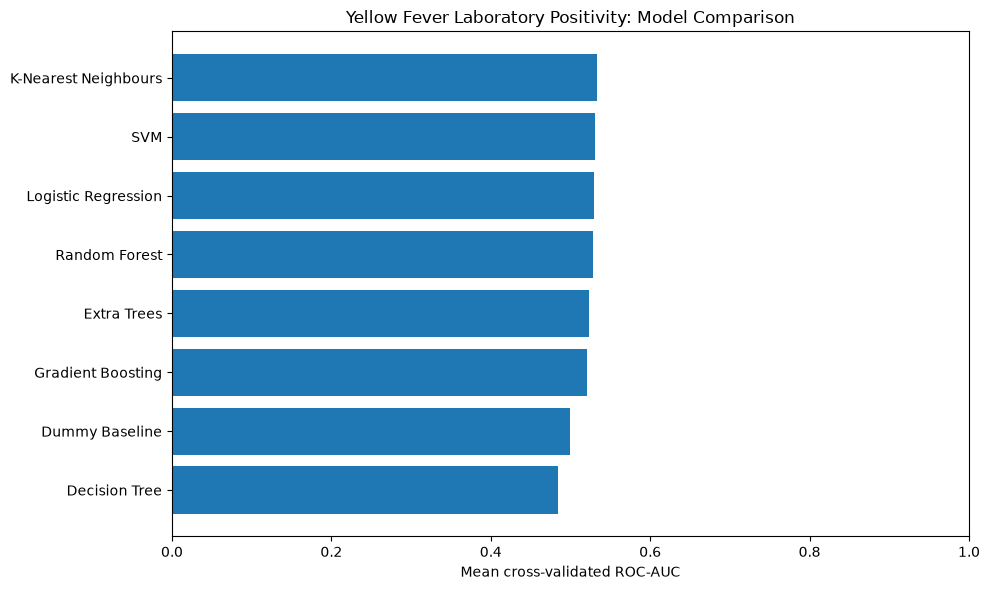

In [48]:

plot_data = cv_results_df.sort_values("ROC-AUC mean")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Model"],
    plot_data["ROC-AUC mean"]
)

plt.xlabel("Mean cross-validated ROC-AUC")
plt.title(
    "Yellow Fever Laboratory Positivity: Model Comparison"
)
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


In [49]:

best_model_name = cv_results_df.loc[
    cv_results_df["ROC-AUC mean"].idxmax(),
    "Model"
]

print("Best model by cross-validated ROC-AUC:", best_model_name)

if best_model_name == "Dummy Baseline":
    raise ValueError(
        "The baseline ranked first. Inspect model performance, "
        "target balance and feature quality before proceeding."
    )

best_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", models[best_model_name])
])

best_pipeline.fit(X_train, y_train)

print("Best model trained successfully.")


Best model by cross-validated ROC-AUC: K-Nearest Neighbours
Best model trained successfully.


In [50]:

# Predict classes and probabilities
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
test_metrics = {
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall / Sensitivity": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

test_metrics_df = pd.DataFrame(
    [test_metrics]
).set_index("Model")

display(test_metrics_df.round(3))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))


,Accuracy,Balanced accuracy,Precision,Recall / Sensitivity,F1-score,ROC-AUC
Model,,,,,,
K-Nearest Neighbours,0.612,0.504,0.343,0.182,0.238,0.513



Classification report:
              precision    recall  f1-score   support

    Negative       0.67      0.83      0.74       540
    Positive       0.34      0.18      0.24       269

    accuracy                           0.61       809
   macro avg       0.51      0.50      0.49       809
weighted avg       0.56      0.61      0.57       809



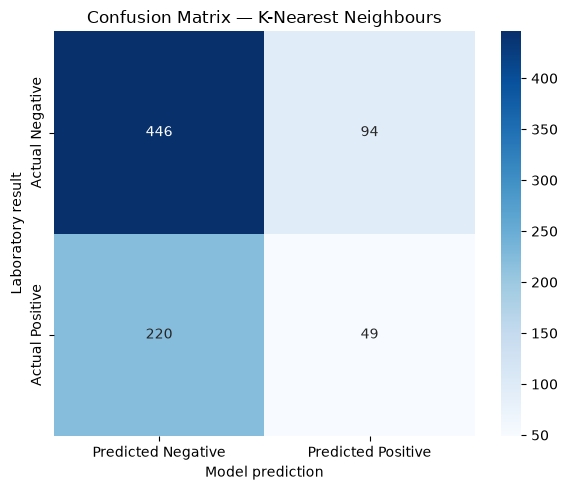

True negatives: 446
False positives: 94
False negatives: 220
True positives: 49


In [51]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Negative", "Predicted Positive"],
    yticklabels=["Actual Negative", "Actual Positive"]
)

plt.xlabel("Model prediction")
plt.ylabel("Laboratory result")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)


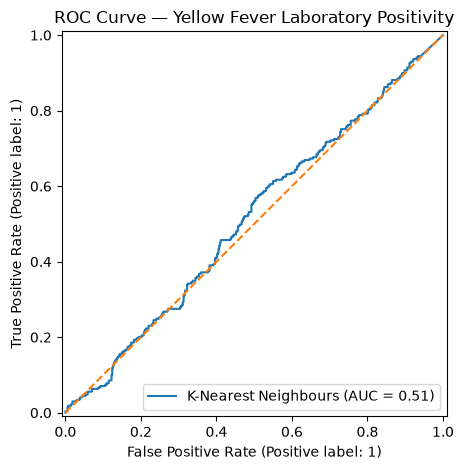

In [52]:

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=best_model_name
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.title("ROC Curve — Yellow Fever Laboratory Positivity")
plt.tight_layout()
plt.show()


,Feature,Importance mean,Importance SD
21,Chills or sweats,0.0176,0.0071
15,Joint pain or arthritis,0.0102,0.0091
14,Muscle pain,0.0102,0.0094
19,Diarrhea,0.0085,0.0064
22,Dehydration,0.0080,0.0137
1,Sex,0.0079,0.0109
13,Fatigue/general weakness,0.0067,0.0061
10,Headache,0.0063,0.0074
24,onset_month,0.0060,0.0119
25,onset_quarter,0.0060,0.0161


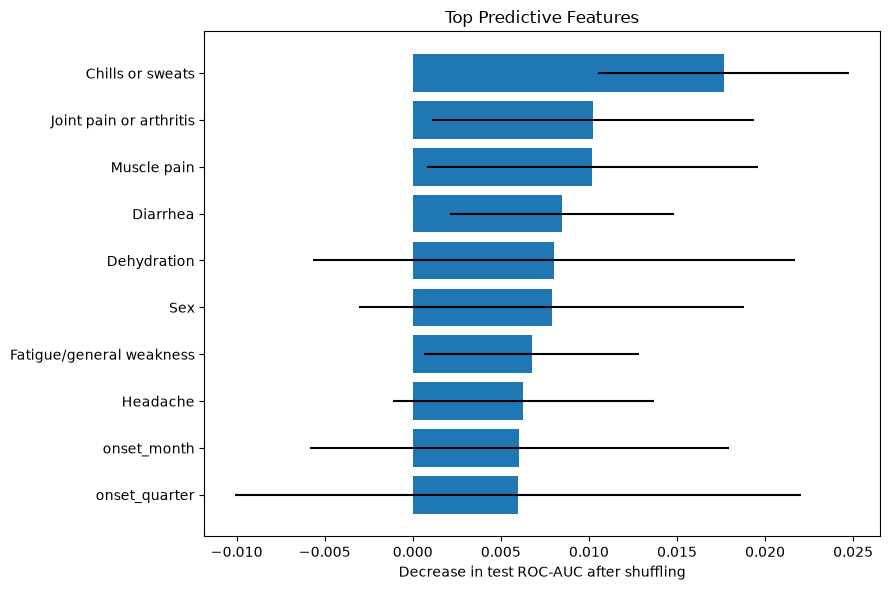

In [53]:

from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance mean": perm.importances_mean,
    "Importance SD": perm.importances_std}).sort_values("Importance mean", ascending=False)

display(importance_df.round(4))

# Plot the ten most important features
top_features = importance_df.head(10).sort_values(
    "Importance mean")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance mean"],
    xerr=top_features["Importance SD"])

plt.xlabel("Decrease in test ROC-AUC after shuffling")
plt.title("Top Predictive Features")
plt.tight_layout()
plt.show()


In [54]:

import joblib
import json
from pathlib import Path

output_dir = Path("yellow_fever_model_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the fitted pipeline
model_path = output_dir / "best_yellow_fever_model.joblib"
joblib.dump(best_pipeline, model_path)

# Save the selected feature list
feature_path = output_dir / "model_features.json"
with open(feature_path, "w", encoding="utf-8") as f:
    json.dump(features, f, indent=2)

# Save the cross-validation comparison
cv_results_df.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# Save final test metrics
test_metrics_df.to_csv(
    output_dir / "best_model_test_metrics.csv"
)

# Save feature importance
importance_df.to_csv(
    output_dir / "permutation_importance.csv",
    index=False
)

# Save model metadata
metadata = {
    "model_name": best_model_name,
    "target_column": target_col,
    "target_mapping": {
        "Positive": 1,
        "Negative": 0
    },
    "selected_features": X.columns.tolist(),
    "test_size": 0.20,
    "random_state": 42,
    "dataset_type": "Simulated educational dataset",
    "intended_task":
        "Classify laboratory positivity among reported cases"
}

with open(
    output_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", model_path.resolve())
print("Saved model comparison, metrics, feature list,")
print("importance results and metadata in:", output_dir.resolve())


Saved model: C:\Users\BLAST\Desktop\PYTHON CLASS\DATA SCIENCE NOTE\yellow_fever_model_outputs\best_yellow_fever_model.joblib
Saved model comparison, metrics, feature list,
importance results and metadata in: C:\Users\BLAST\Desktop\PYTHON CLASS\DATA SCIENCE NOTE\yellow_fever_model_outputs


In [55]:


# Load the saved pipeline
loaded_model = joblib.load(
    "yellow_fever_model_outputs/best_yellow_fever_model.joblib"
)

# Predict on a few held-out test records
sample_X = X_test.head(5)

sample_probabilities = loaded_model.predict_proba(sample_X)[:, 1]
sample_predictions = loaded_model.predict(sample_X)

prediction_check = pd.DataFrame({
    "Predicted probability of positive result": sample_probabilities,
    "Predicted class": sample_predictions
}, index=sample_X.index)

display(prediction_check)



,Predicted probability of positive result,Predicted class
1637,0.137782,0
2212,0.145623,0
2962,0.278346,0
2089,0.139766,0
3125,0.412909,0
